# Phase 5 — Customer Segmentation & Retention Prioritization
**Project:** Customer Churn & Retention Analytics Platform  
**Target:** Data Analyst / Business Intelligence Portfolio  
**Objective:** Classify customer base along Multi-Dimensional Axes (Tenure, Revenue Value, Churn Risk) and build the 2x2 Strategic Retention Matrix to prioritize high-value at-risk accounts.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/processed/customers_cleaned.csv')
print(f"Loaded {len(df)} customer records for segmentation.")
df.head(3)


Loaded 7043 customer records for segmentation.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,CustomerValueSegment,ContractCategory,PaymentCategory,ServiceCount,HasInternet,HasTechSupport,HasOnlineSecurity,RiskScore,ChurnRiskSegment,StrategicSegment
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,Low Value,Month-to-month,Manual,1,1,0,0,4,High Risk,Low/Med Value + High Risk (At-Risk Core)
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Medium Value,One year,Manual,3,1,0,1,0,Low Risk,Low/Med Value + Low/Med Risk (Stable Core)
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,Medium Value,Month-to-month,Manual,3,1,0,1,3,Medium Risk,Low/Med Value + Low/Med Risk (Stable Core)


## 1. Multi-Dimensional Segmentation Breakdown
We segment along 4 key business dimensions:
1. **Tenure Lifecycle Cohort:** New (0-1 yr), Growing (1-2 yrs), Established (2-4 yrs), Loyal (4+ yrs)
2. **Customer Value Segment:** Low Value (<$35), Medium Value ($35-$70), High Value (>$70)
3. **Churn Risk Tier:** High Risk, Medium Risk, Low Risk
4. **Strategic 2x2 Quadrant:** Value vs Risk Matrix


In [2]:
# Dimension 1: Value Segment
val_summary = df.groupby('CustomerValueSegment').agg(
    Customers=('customerID', 'count'),
    Pct_Customers=('customerID', lambda s: len(s) / len(df) * 100),
    Avg_Monthly_Spend=('MonthlyCharges', 'mean'),
    Total_Monthly_Rev=('MonthlyCharges', 'sum'),
    Churn_Rate=('ChurnFlag', lambda s: s.mean() * 100)
).reindex(['Low Value', 'Medium Value', 'High Value'])
val_summary


,Customers,Pct_Customers,Avg_Monthly_Spend,Total_Monthly_Rev,Churn_Rate
CustomerValueSegment,,,,,
Low Value,1731,24.577595,21.997198,38077.15,10.860774
Medium Value,1729,24.549198,54.793031,94737.15,23.944477
High Value,3583,50.873207,90.232291,323302.30,35.361429


In [3]:
# Dimension 2: Risk Tier
risk_summary = df.groupby('ChurnRiskSegment').agg(
    Customers=('customerID', 'count'),
    Churned=('ChurnFlag', 'sum'),
    Churn_Rate=('ChurnFlag', lambda s: s.mean() * 100),
    Monthly_Rev_At_Risk=('MonthlyRevenue', lambda s: s[df.loc[s.index, 'ChurnFlag'] == 1].sum())
).reindex(['High Risk', 'Medium Risk', 'Low Risk'])
risk_summary


,Customers,Churned,Churn_Rate,Monthly_Rev_At_Risk
ChurnRiskSegment,,,,
High Risk,2332,1287,55.188679,104233.00
Medium Risk,2135,467,21.873536,26418.80
Low Risk,2576,115,4.464286,8479.05


## 2. Strategic 2x2 Retention Quadrant
The core decision framework for retention strategy:
- **High Value + High Risk (Retention Priority):** Immediate outreach, VIP care, contract renewal discounts.
- **High Value + Low/Med Risk (Loyal Champions):** Cross-selling, loyalty perks, referral programs.
- **Low/Med Value + High Risk (At-Risk Core):** Automated email/SMS check-ins, self-service tools.
- **Low/Med Value + Low/Med Risk (Stable Core):** Low-touch maintenance.


In [4]:
quadrant_summary = df.groupby('StrategicSegment').agg(
    Total_Customers=('customerID', 'count'),
    Pct_Base=('customerID', lambda s: len(s) / len(df) * 100),
    Churned_Count=('ChurnFlag', 'sum'),
    Churn_Rate_Pct=('ChurnFlag', lambda s: s.mean() * 100),
    Monthly_Rev_At_Risk=('MonthlyRevenue', lambda s: s[df.loc[s.index, 'ChurnFlag'] == 1].sum()),
    Annual_Rev_At_Risk=('MonthlyRevenue', lambda s: s[df.loc[s.index, 'ChurnFlag'] == 1].sum() * 12)
)
quadrant_summary


,Total_Customers,Pct_Base,Churned_Count,Churn_Rate_Pct,Monthly_Rev_At_Risk,Annual_Rev_At_Risk
StrategicSegment,,,,,,
High Value + High Risk (Retention Priority),1912,27.147522,1071,56.014644,93343.50,1120122.0
High Value + Low/Med Risk (Loyal Champions),1671,23.725685,196,11.729503,19147.50,229770.0
Low/Med Value + High Risk (At-Risk Core),420,5.963368,216,51.428571,10889.50,130674.0
Low/Med Value + Low/Med Risk (Stable Core),3040,43.163425,386,12.697368,15750.35,189004.2


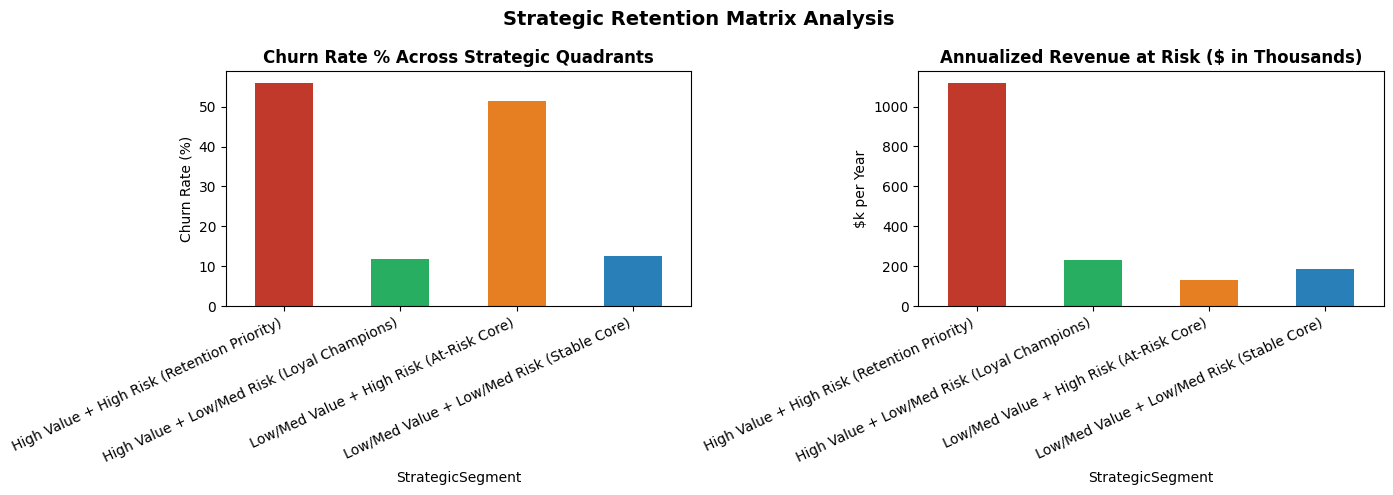

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

quadrant_summary['Churn_Rate_Pct'].plot(kind='bar', ax=ax1, color=['#c0392b', '#27ae60', '#e67e22', '#2980b9'])
ax1.set_title("Churn Rate % Across Strategic Quadrants", fontsize=12, weight='bold')
ax1.set_ylabel("Churn Rate (%)")
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=25, ha='right')

(quadrant_summary['Annual_Rev_At_Risk'] / 1000).plot(kind='bar', ax=ax2, color=['#c0392b', '#27ae60', '#e67e22', '#2980b9'])
ax2.set_title("Annualized Revenue at Risk ($ in Thousands)", fontsize=12, weight='bold')
ax2.set_ylabel("$k per Year")
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=25, ha='right')

plt.suptitle("Strategic Retention Matrix Analysis", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()


## 3. High-Value At-Risk Target List Export
Generate the tactical list of highest priority customer accounts for Customer Success and Retention teams.


In [6]:
target_accounts = df[
    (df['CustomerValueSegment'] == 'High Value') &
    (df['Contract'] == 'Month-to-month') &
    (df['ChurnFlag'] == 0) # Currently active, but vulnerable to churn
].sort_values(by='MonthlyCharges', ascending=False)

print(f"Total High-Priority Active At-Risk Accounts: {len(target_accounts)}")
print(f"Total Monthly Recurring Revenue from these accounts: ${target_accounts['MonthlyCharges'].sum():,.2f}")
print(f"Total Annual Recurring Revenue: ${target_accounts['MonthlyCharges'].sum() * 12:,.2f}")

target_accounts[['customerID', 'tenure', 'MonthlyCharges', 'InternetService', 'TechSupport', 'PaymentMethod']].head(10)


Total High-Priority Active At-Risk Accounts: 992
Total Monthly Recurring Revenue from these accounts: $86,948.00
Total Annual Recurring Revenue: $1,043,376.00


,customerID,tenure,MonthlyCharges,InternetService,TechSupport,PaymentMethod
5137,8016-NCFVO,55,116.50,Fiber optic,Yes,Electronic check
1668,9659-QEQSY,45,115.65,Fiber optic,Yes,Electronic check
3856,6710-HSJRD,61,114.10,Fiber optic,Yes,Electronic check
440,0771-WLCLA,16,112.95,Fiber optic,Yes,Electronic check
3820,9481-IEBZY,72,112.90,Fiber optic,Yes,Credit card (automatic)
3669,2587-EKXTS,44,111.50,Fiber optic,No,Electronic check
1357,7130-YXBRO,48,111.45,Fiber optic,No,Bank transfer (automatic)
1568,3292-PBZEJ,11,111.40,Fiber optic,Yes,Electronic check
197,6168-YBYNP,59,111.35,Fiber optic,Yes,Electronic check
5004,2067-QYTCF,64,111.15,Fiber optic,Yes,Electronic check
